# 04 · Modelo de clustering de platos · Objetivo 1 (con MLflow)

## ¿Qué hacemos en este notebook?
En el notebook 03 exploramos los datos y vimos que lo razonable es **agrupar los 80 platos por su rendimiento** usando dos variables: `popularidad` (cuánto se piden) y `margen_medio` (cuánto dinero dejan). Aquí **construimos el modelo**:

1. Probamos dos algoritmos de agrupación (**K-Means** y **clustering jerárquico**) con distinto número de grupos.
2. Medimos con varias notas lo bien que agrupa cada prueba.
3. **Elegimos el número de grupos con reglas claras**, no a ojo.
4. Entrenamos el modelo final, ponemos nombre a cada grupo y lo guardamos.

## ¿Qué es MLflow y por qué lo usamos?
Cuando se prueban varios modelos con distintos ajustes es muy fácil perder la pista: *¿qué número de grupos usé en aquella prueba? ¿con qué datos? ¿qué nota sacó?* **MLflow es un cuaderno de laboratorio automático**: cada prueba queda apuntada con sus ajustes, sus resultados, sus gráficos y el propio modelo, y todo se puede consultar y comparar en una página web. Así cualquiera del equipo puede ver **qué se probó y por qué se eligió el modelo final**.

En este notebook MLflow guarda:
- **Una ejecución "padre"** que agrupa las pruebas, y **una ejecución "hija" por cada prueba** (algoritmo + número de grupos).
- **El modelo final**, registrado con nombre y versión, para poder recuperarlo y usarlo después.

Para verlo en el navegador: **http://localhost:5000**.

## Requisitos
- El servicio `mlflow` tiene que estar arrancado (desde la carpeta `docker/`: `docker compose up -d --build`).
- Tienen que existir `platos_features.parquet` (lo deja el notebook 03).

**Cómo ejecutarlo:** *Kernel → Restart & Run All*. Cada vez que se ejecuta se guardan **nuevas** ejecuciones en MLflow (el historial no se borra), y el modelo final sube una versión.

**Índice**
- Guía rápida de conceptos
- 0. Configuración y funciones
- 1. Conexión con MLflow y carga de datos
- 2. Preparación de las variables
- 3. Experimentos: algoritmos y número de grupos
- 4. Elegir el número de grupos
- 5. Modelo final y perfil de los grupos
- 6. Registrar el modelo en MLflow
- 7. Comprobar que el modelo guardado funciona
- 8. Guardar el resultado
- 9. Cómo verlo en MLflow
- 10. Conclusiones

---
## Guía rápida de conceptos

**Clustering** (conceptos nuevos respecto al notebook 03; K-Means, estandarizar y silhouette ya se explicaron allí)

| Concepto | Qué significa, en sencillo |
|---|---|
| **Centroide** | El "centro" de un grupo: el punto medio de todos los platos que lo forman. K-Means asigna cada plato al centroide más cercano. |
| **Inercia** | Suma de las distancias de cada plato a su centroide. **Siempre baja al añadir grupos**, así que no sirve sola para elegir *k*; se usa para ver dónde deja de bajar mucho (el "codo"). |
| **Davies-Bouldin** | Nota de lo **mezclados** que están los grupos. **Cuanto más baja, mejor** (0 sería perfecto). |
| **Calinski-Harabasz** | Nota de lo **separados y compactos** que están los grupos. **Cuanto más alta, mejor**. |
| **Estabilidad** | Se repite K-Means 10 veces con puntos de partida al azar distintos y se mira si salen los mismos grupos. Si cada vez sale algo distinto, los grupos no son de fiar. |
| **ARI** (*Adjusted Rand Index*) | Nota que compara **dos agrupaciones**: 1 = los mismos grupos, 0 = tan parecidas como dos agrupaciones hechas al azar. La usamos para la estabilidad y para comparar K-Means con el jerárquico. |
| **Clustering jerárquico (Ward)** | Otra forma de agrupar: empieza con cada plato solo y va **juntando los dos grupos más parecidos**, una y otra vez, hasta que queda uno. Se puede "cortar" donde queramos para tener *k* grupos. |
| **Dendrograma** | El dibujo en forma de árbol de ese proceso: cuanto más arriba se unen dos ramas, más distintos son esos platos. |
| **Pipeline** | Una cadena de pasos que se guarda como **un único objeto**: primero estandarizar y luego agrupar. Así, un plato nuevo recibe exactamente el mismo tratamiento. |

**MLflow**

| Concepto | Qué significa, en sencillo |
|---|---|
| **Servidor de seguimiento** (*tracking server*) | El programa que **guarda y muestra** todo lo apuntado. Vive en el contenedor `mlflow` y se ve en http://localhost:5000. |
| **Experimento** | Una carpeta que agrupa todas las pruebas de un mismo problema. El nuestro: `smart-restaurant-clustering-platos`. |
| **Run** (ejecución) | **Una prueba concreta**. Un *run* anidado es un run hijo dentro de otro (padre). |
| **Parámetro** | Un ajuste que **elegimos nosotros** antes de probar (por ejemplo, `k = 4`). |
| **Métrica** | Un resultado **medido** después (por ejemplo, el silhouette). |
| **Artefacto** | Un archivo que acompaña a la prueba: un gráfico, una tabla, el modelo. |
| **Modelo registrado** | El modelo final guardado **con nombre y número de versión**, listo para recuperarlo. |
| **Alias** | Una etiqueta que apunta a una versión (por ejemplo `actual`), para pedir "el modelo actual" sin saber su número. |

---
## 0. Configuración y funciones

**Configuración:** todo lo que se puede cambiar está **en una sola celda**: rutas, variables, reglas para elegir el número de grupos, nombres en MLflow y colores.

**Funciones:** son "recetas" que se escriben una vez y se usan varias veces. Cada una lleva debajo, entre comillas, la descripción de lo que hace.

In [1]:
from __future__ import annotations   # permite usar list[str] o dict[str, float] en versiones antiguas de Python

import hashlib
import os

import matplotlib.pyplot as plt
import mlflow
import mlflow.sklearn
import numpy as np
import pandas as pd
import requests
import seaborn as sns
from mlflow.models import infer_signature
from mlflow.tracking import MlflowClient
from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.cluster import AgglomerativeClustering, KMeans
from sklearn.metrics import (adjusted_rand_score, calinski_harabasz_score, davies_bouldin_score,
                             silhouette_score)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

# ---------- Rutas: HDFS por WebHDFS (las variables de entorno las pone el contenedor de Docker) ----------
HOST = os.environ.get("HDFS_WEBHDFS_URL", "http://namenode:9870").replace("http://", "")
OPT = {"user": os.environ.get("HDFS_USER", "root")}
CLEAN = f"webhdfs://{HOST}/datalake/clean"
RUTA_PLATOS = f"{CLEAN}/ventas_diarias_platos/platos_features.parquet"     # ENTRADA: la deja el notebook 03
RUTA_CLUSTERS = f"{CLEAN}/ventas_diarias_platos/platos_clusters.parquet"   # SALIDA: platos con su grupo

# ---------- MLflow ----------
MLFLOW_URI = os.environ.get("MLFLOW_TRACKING_URI", "http://mlflow:5000")   # dirección del servidor MLflow
NOMBRE_EXPERIMENTO = "smart-restaurant-clustering-platos"                  # carpeta donde se agrupan las pruebas
NOMBRE_MODELO = "smart_restaurant_clustering_platos"                       # nombre del modelo registrado
ALIAS_MODELO = "actual"                                                    # etiqueta de la versión vigente

# ---------- Variables y parámetros del modelo ----------
VARIABLES = ["popularidad", "margen_medio"]    # con qué variables se agrupa (decisión del notebook 03)
VARIABLES_PERFIL = ["popularidad", "margen_medio", "precio_medio", "coste_medio",
                    "valoracion", "dificultad", "unidades_medias"]   # para describir los grupos después
N_PLATOS_ESPERADOS = 80
RANDOM_STATE = 42           # misma semilla en todo: los resultados se pueden repetir
N_INIT = 10                 # K-Means se repite 10 veces con puntos de partida distintos y se queda con el mejor
N_SEMILLAS_ESTABILIDAD = 10 # nº de repeticiones para medir la estabilidad
K_PROBADOS = range(2, 7)    # probamos de 2 a 6 grupos
K_CODO = range(2, 11)       # solo para el gráfico del codo: llegamos hasta 10 para ver cómo se aplana la curva

# ---------- Reglas para elegir el número de grupos (se explican en la sección 4) ----------
TOLERANCIA_SILHOUETTE = 0.03   # el silhouette puede quedar como mucho 0,03 por debajo del mejor
MIN_ESTABILIDAD = 0.80         # estabilidad (ARI entre repeticiones) mínima
MIN_TAM_GRUPO = 0.10           # el grupo más pequeño debe tener al menos el 10 % de los platos
MIN_ACUERDO = 0.70             # acuerdo mínimo (ARI) entre K-Means y el clustering jerárquico

# ---------- Colores de Smart-Restaurant ----------
AZUL = "#1F3A44"
NARANJA = "#F28C38"
GRIS_AZULADO = "#5C808E"
MELOCOTON = "#FFE0C2"
COLORES_GRUPOS = [AZUL, NARANJA, GRIS_AZULADO, "#C4621A", "#8FB3C0", "#E8B98A"]   # para grupos sin nombre
COLOR_POR_NOMBRE = {                      # con nombre: el color indica de qué tipo de grupo se trata
    "Estrella (popular y rentable)": NARANJA,
    "Popular pero poco rentable": "#E8B98A",
    "Rentable pero poco popular": GRIS_AZULADO,
    "Bajo rendimiento (poco popular y poco rentable)": AZUL,
}

sns.set_theme(style="whitegrid", font="DejaVu Sans")
plt.rcParams.update({"figure.dpi": 100, "axes.titleweight": "bold", "axes.titlesize": 11,
                     "axes.edgecolor": GRIS_AZULADO, "axes.labelcolor": AZUL, "text.color": AZUL})
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

In [2]:
def validar(condicion: bool, mensaje: str) -> None:
    """Comprueba algo que DEBE cumplirse. Si falla, el notebook se detiene con un mensaje claro."""
    assert condicion, f"FALLO: {mensaje}"
    print(f"OK · {mensaje}")


def conectar_mlflow(uri: str, nombre_experimento: str):
    """Conecta con el servidor MLflow y selecciona (o crea) el experimento. Falla rápido y con un mensaje claro."""
    try:
        requests.get(f"{uri}/health", timeout=5).raise_for_status()      # "ping" al servidor
    except Exception as error:
        raise RuntimeError(
            f"No se puede conectar con MLflow en {uri}. ¿Está arrancado el servicio? "
            "Desde la carpeta docker/ ejecuta: docker compose up -d --build") from error
    mlflow.set_tracking_uri(uri)
    return mlflow.set_experiment(nombre_experimento)


def evaluar_particion(X: np.ndarray, etiquetas: np.ndarray) -> dict[str, float]:
    """Calcula las notas de una agrupación: silhouette, Davies-Bouldin, Calinski-Harabasz y tamaños de grupo."""
    tamanos = np.bincount(etiquetas)
    return {
        "silhouette": silhouette_score(X, etiquetas),                 # más alto = mejor (máx. 1)
        "davies_bouldin": davies_bouldin_score(X, etiquetas),         # más bajo = mejor
        "calinski_harabasz": calinski_harabasz_score(X, etiquetas),   # más alto = mejor
        "tam_grupo_min": int(tamanos.min()),                          # platos del grupo más pequeño
        "tam_grupo_max": int(tamanos.max()),                          # platos del grupo más grande
    }


def estabilidad_kmeans(X: np.ndarray, k: int, referencia: np.ndarray) -> float:
    """Mide si K-Means da siempre los mismos grupos.

    Repite K-Means con puntos de partida al azar distintos (una sola inicialización cada vez) y compara cada
    resultado con la agrupación de referencia usando el ARI. Devuelve la media: 1 = siempre lo mismo.
    """
    aris = [adjusted_rand_score(referencia, KMeans(n_clusters=k, n_init=1, random_state=semilla).fit_predict(X))
            for semilla in range(N_SEMILLAS_ESTABILIDAD)]
    return float(np.mean(aris))


def figura_grupos(platos: pd.DataFrame, etiquetas, titulo: str, nombres: dict | None = None,
                  centroides: np.ndarray | None = None):
    """Dibuja los platos en el plano popularidad (eje x) y margen (eje y), coloreados por grupo.

    Si se pasan `nombres` (grupo -> nombre) se usan en la leyenda; si se pasan `centroides`, se marcan con una X.
    Se dibujan también las medianas (líneas discontinuas), que dividen el plano en cuatro "cuadrantes".
    """
    fig, ax = plt.subplots(figsize=(10, 5))
    for g in sorted(set(etiquetas)):
        dentro = np.asarray(etiquetas) == g
        color = COLOR_POR_NOMBRE.get(nombres[g]) if nombres else None        # color según el tipo de grupo…
        color = color or COLORES_GRUPOS[g % len(COLORES_GRUPOS)]             # …o uno de la lista si no tiene nombre
        ax.scatter(platos.loc[dentro, "popularidad"], platos.loc[dentro, "margen_medio"],
                   color=color, s=55, edgecolor=AZUL, linewidth=0.5,
                   label=(nombres[g] if nombres else f"grupo {g}") + f" ({dentro.sum()} platos)")
    if centroides is not None:
        ax.scatter(centroides[:, 0], centroides[:, 1], marker="X", s=170, color="white",
                   edgecolor=AZUL, linewidth=1.5, zorder=5, label="centroide")
    ax.axvline(platos["popularidad"].median(), color=GRIS_AZULADO, linestyle="--", linewidth=0.9)
    ax.axhline(platos["margen_medio"].median(), color=GRIS_AZULADO, linestyle="--", linewidth=0.9)
    ax.set_xlabel("popularidad (unidades vendidas / cliente)")
    ax.set_ylabel("margen medio (€)")
    ax.set_title(titulo)
    ax.legend(fontsize=8, loc="center left", bbox_to_anchor=(1.01, 0.5), frameon=True)   # leyenda fuera del gráfico
    fig.tight_layout()
    return fig


def elegir_k(resultados: pd.DataFrame) -> tuple[int, pd.DataFrame]:
    """Elige el número de grupos con las cuatro reglas de la configuración.

    Devuelve (k elegido, tabla con qué reglas cumple cada k). Se elige el k MÁS PEQUEÑO que cumple todas
    (a igualdad de calidad, mejor menos grupos: son más fáciles de explicar). Si ninguno las cumple todas,
    se queda con el de mayor silhouette y avisa.
    """
    km = resultados[resultados["algoritmo"] == "kmeans"].set_index("k")
    n_platos = N_PLATOS_ESPERADOS
    reglas = pd.DataFrame({
        "silhouette cerca del mejor": km["silhouette"] >= km["silhouette"].max() - TOLERANCIA_SILHOUETTE,
        "estable": km["estabilidad"] >= MIN_ESTABILIDAD,
        "grupos no diminutos": km["tam_grupo_min"] / n_platos >= MIN_TAM_GRUPO,
        "acuerdo con el jerárquico": km["acuerdo_entre_algoritmos"] >= MIN_ACUERDO,
    })
    reglas["cumple todas"] = reglas.all(axis=1)
    if reglas["cumple todas"].any():
        return int(reglas.index[reglas["cumple todas"]].min()), reglas
    print("AVISO: ningún k cumple todas las reglas; se elige el de mayor silhouette.")
    return int(km["silhouette"].idxmax()), reglas


def nombrar_grupos(centroides_z: np.ndarray) -> dict[int, str]:
    """Pone nombre a cada grupo según si su centroide queda por encima o por debajo de la media en cada variable.

    `centroides_z` tiene una fila por grupo y dos columnas: popularidad y margen, ya estandarizadas
    (0 = media de todos los platos). Positivo = por encima de la media.
    """
    nombres = {}
    for g, (pop_z, margen_z) in enumerate(centroides_z):
        if pop_z > 0 and margen_z > 0:
            nombres[g] = "Estrella (popular y rentable)"
        elif pop_z > 0:
            nombres[g] = "Popular pero poco rentable"
        elif margen_z > 0:
            nombres[g] = "Rentable pero poco popular"
        else:
            nombres[g] = "Bajo rendimiento (poco popular y poco rentable)"
    return nombres


def guardar_parquet(df: pd.DataFrame, ruta: str) -> None:
    """Guarda la tabla en Parquet, la vuelve a leer y comprueba que quedó igual (mismas filas y columnas)."""
    df.to_parquet(ruta, storage_options=OPT, index=False)
    leido = pd.read_parquet(ruta, storage_options=OPT)
    validar(leido.shape == df.shape and list(leido.columns) == list(df.columns),
            f"guardado en {ruta.split('/datalake/')[-1]} · {leido.shape[0]} filas × {leido.shape[1]} columnas")

---
## 1. Conexión con MLflow y carga de datos

**Qué hacemos:** primero comprobamos que el servidor MLflow responde y seleccionamos nuestro experimento (si no existe, se crea). Después cargamos `platos_features.parquet`, la tabla de **una fila por plato** del notebook 03, y comprobamos con `validar(...)` que es lo que esperamos.

In [3]:
# Conectamos con MLflow: si el servicio no está arrancado, aquí falla con un mensaje que explica qué hacer
experimento = conectar_mlflow(MLFLOW_URI, NOMBRE_EXPERIMENTO)
print(f"Servidor MLflow: {MLFLOW_URI}")
print(f"Experimento: {experimento.name} (id {experimento.experiment_id})")

Servidor MLflow: http://mlflow:5000
Experimento: smart-restaurant-clustering-platos (id 1)


In [4]:
# Cargamos la tabla de platos (una fila por plato)
platos = pd.read_parquet(RUTA_PLATOS, storage_options=OPT)

# Comprobaciones: lo que damos por supuesto
validar(len(platos) == N_PLATOS_ESPERADOS, f"hay {N_PLATOS_ESPERADOS} platos (una fila por plato)")
validar(platos["id_plato"].is_unique, "no hay platos repetidos")
validar(set(VARIABLES_PERFIL) <= set(platos.columns), "están todas las columnas que necesitamos")
validar(int(platos[VARIABLES_PERFIL].isna().sum().sum()) == 0, "no hay vacíos en las variables")

display(platos.head())

OK · hay 80 platos (una fila por plato)
OK · no hay platos repetidos
OK · están todas las columnas que necesitamos
OK · no hay vacíos en las variables


,id_plato,n_filas,unidades_medias,popularidad,precio_medio,coste_medio,margen_medio,valoracion,dificultad
0,1,1311,24.542,0.510,16.151,6.168,9.983,4.000,4
1,2,1264,24.619,0.518,15.749,6.032,9.718,4.800,7
2,3,1285,25.088,0.518,16.028,6.089,9.939,4.900,7
3,4,1331,24.592,0.502,15.834,5.983,9.851,3.900,3
4,5,1294,25.143,0.522,15.685,6.091,9.594,4.100,7


---
## 2. Preparación de las variables

**Qué hacemos:** nos quedamos con las dos variables con las que vamos a agrupar (`popularidad` y `margen_medio`) y las **estandarizamos**: cada una pasa a tener media 0 y desviación típica 1. Así las dos pesan igual en el cálculo de distancias, aunque una vaya en euros (≈ 10) y la otra entre 0 y 1 (≈ 0,5).

**Cómo leer el resultado:** tras estandarizar, un plato con valor **0** está justo en la media de todos los platos; **+1** está una desviación típica por encima y **−1** una por debajo.

También calculamos una **huella** de los datos (un código corto que cambia si cambia cualquier valor). Se guarda en MLflow para saber, más adelante, con qué datos exactos se hizo cada prueba.

In [5]:
# Matriz con las dos variables de cada plato (80 filas x 2 columnas)
datos_modelo = platos[VARIABLES]

# Estandarización: media 0 y desviación típica 1 en cada columna.
# Aquí se usa solo para probar y comparar algoritmos; el modelo final llevará el estandarizador dentro (Pipeline).
X = StandardScaler().fit_transform(datos_modelo)

# Huella de los datos: si el parquet cambia, la huella cambia
huella_datos = hashlib.md5(pd.util.hash_pandas_object(datos_modelo, index=False).values.tobytes()).hexdigest()[:12]

print("Forma de la matriz:", X.shape)
print("Media de cada columna tras estandarizar:", X.mean(axis=0).round(3))
print("Desviación típica:", X.std(axis=0).round(3))
print("Huella de los datos:", huella_datos)

Forma de la matriz: (80, 2)
Media de cada columna tras estandarizar: [-0. -0.]
Desviación típica: [1. 1.]
Huella de los datos: aa931185b165


---
## 3. Experimentos: algoritmos y número de grupos

**Qué hacemos:** probamos **dos algoritmos** (K-Means y clustering jerárquico Ward) con **2, 3, 4, 5 y 6 grupos**: 10 pruebas. Para cada una calculamos las notas de la sección «Guía rápida de conceptos» y **lo apuntamos todo en MLflow**:

- **Ejecución padre** (`comparacion_algoritmos_y_k`): guarda los ajustes comunes, la huella de los datos y el dendrograma.
- **Una ejecución hija por prueba** (por ejemplo `kmeans_k4`): guarda sus **parámetros** (algoritmo, *k*), sus **métricas** y un **gráfico** con los grupos.

Además de las notas habituales calculamos dos que nos dirán si los grupos son de fiar:
- **`estabilidad`** (solo K-Means): ¿salen los mismos grupos si repetimos con otros puntos de partida?
- **`acuerdo_entre_algoritmos`**: ¿K-Means y el jerárquico forman los mismos grupos? Si dos formas distintas de agrupar coinciden, los grupos son más sólidos.

In [6]:
def ejecutar_experimentos(X: np.ndarray, platos: pd.DataFrame) -> tuple[pd.DataFrame, plt.Figure]:
    """Prueba K-Means y jerárquico con cada k, lo apunta todo en MLflow y devuelve la tabla de resultados.

    Devuelve también la figura del dendrograma (el árbol del clustering jerárquico) para poder mostrarla.
    """
    # 1) Calculamos todas las agrupaciones primero, para poder comparar un algoritmo con el otro
    agrupaciones = {}   # (algoritmo, k) -> (etiquetas, centroides o None, inercia o None)
    for k in K_PROBADOS:
        km = KMeans(n_clusters=k, n_init=N_INIT, random_state=RANDOM_STATE).fit(X)
        agrupaciones[("kmeans", k)] = (km.labels_, km.cluster_centers_, km.inertia_)
        ag = AgglomerativeClustering(n_clusters=k, linkage="ward").fit(X)
        agrupaciones[("jerarquico", k)] = (ag.labels_, None, None)

    # 2) Dendrograma: el árbol de uniones del clustering jerárquico
    fig_dendro, ax = plt.subplots(figsize=(13, 4))
    dendrogram(linkage(X, method="ward"), labels=platos["id_plato"].tolist(), leaf_font_size=7,
               color_threshold=0, above_threshold_color=AZUL, ax=ax)
    ax.set_title("Dendrograma del clustering jerárquico (cada hoja es un plato)")
    ax.set_xlabel("id_plato")
    ax.set_ylabel("distancia a la que se unen")
    fig_dendro.tight_layout()

    # 3) Ejecución padre + una hija por prueba
    filas = []
    with mlflow.start_run(run_name="comparacion_algoritmos_y_k"):
        mlflow.set_tag("fase", "comparacion")
        mlflow.log_params({"variables": ",".join(VARIABLES), "preprocesado": "StandardScaler",
                           "k_probados": f"{min(K_PROBADOS)}-{max(K_PROBADOS)}", "n_platos": len(platos),
                           "huella_datos": huella_datos, "random_state": RANDOM_STATE})
        mlflow.log_figure(fig_dendro, "dendrograma.png")
        plt.close(fig_dendro)       # lo mostraremos más abajo, una sola vez

        for (algoritmo, k), (etiquetas, centroides, inercia) in agrupaciones.items():
            otro = "jerarquico" if algoritmo == "kmeans" else "kmeans"
            metricas = evaluar_particion(X, etiquetas)
            metricas["acuerdo_entre_algoritmos"] = adjusted_rand_score(etiquetas, agrupaciones[(otro, k)][0])
            if algoritmo == "kmeans":
                metricas["inercia"] = inercia
                metricas["estabilidad"] = estabilidad_kmeans(X, k, etiquetas)

            with mlflow.start_run(run_name=f"{algoritmo}_k{k}", nested=True):
                mlflow.set_tag("fase", "comparacion")
                mlflow.log_params({"algoritmo": algoritmo, "k": k,
                                   "linkage": "ward" if algoritmo == "jerarquico" else "no aplica"})
                mlflow.log_metrics(metricas)
                fig = figura_grupos(platos, etiquetas, f"{algoritmo} con {k} grupos")
                mlflow.log_figure(fig, "grupos.png")
                plt.close(fig)        # no los mostramos todos: quedan guardados en MLflow
            filas.append({"algoritmo": algoritmo, "k": k, **metricas})

    return pd.DataFrame(filas), fig_dendro


resultados, fig_dendro = ejecutar_experimentos(X, platos)
print(f"Se han apuntado {len(resultados)} pruebas en MLflow (más la ejecución padre).")

🏃 View run kmeans_k2 at: http://mlflow:5000/#/experiments/1/runs/b933c39c8c6e46a6a8c8c8c7794fb8f6
🧪 View experiment at: http://mlflow:5000/#/experiments/1
🏃 View run jerarquico_k2 at: http://mlflow:5000/#/experiments/1/runs/964dbabf91c64c41bdc49eabe8d73a8d
🧪 View experiment at: http://mlflow:5000/#/experiments/1
🏃 View run kmeans_k3 at: http://mlflow:5000/#/experiments/1/runs/310d0aa2a2e14450b3ab9312602ba4c9
🧪 View experiment at: http://mlflow:5000/#/experiments/1
🏃 View run jerarquico_k3 at: http://mlflow:5000/#/experiments/1/runs/4572a503d65c4fd494eca8d4fd871467
🧪 View experiment at: http://mlflow:5000/#/experiments/1
🏃 View run kmeans_k4 at: http://mlflow:5000/#/experiments/1/runs/5b61f454dff14e06b0c68e3b3f27c44d
🧪 View experiment at: http://mlflow:5000/#/experiments/1
🏃 View run jerarquico_k4 at: http://mlflow:5000/#/experiments/1/runs/80eb9b6448eb42cfa197d4ad59ea9a2e
🧪 View experiment at: http://mlflow:5000/#/experiments/1
🏃 View run kmeans_k5 at: http://mlflow:5000/#/experiments/

### Resultados de las 10 pruebas
Cada fila es una prueba. **Cómo leerla:**
- `silhouette` y `calinski_harabasz`: **más alto = mejor**. `davies_bouldin`: **más bajo = mejor**.
- `tam_grupo_min` y `tam_grupo_max`: platos del grupo más pequeño y del más grande. Un grupo de 3 o 4 platos no sería un grupo útil.
- `acuerdo_entre_algoritmos`: ARI entre K-Means y jerárquico (1 = mismos grupos).
- `inercia` y `estabilidad`: solo para K-Means.

In [7]:
columnas_tabla = ["algoritmo", "k", "silhouette", "davies_bouldin", "calinski_harabasz", "tam_grupo_min",
                  "tam_grupo_max", "acuerdo_entre_algoritmos", "inercia", "estabilidad"]
display(resultados[columnas_tabla].set_index(["algoritmo", "k"]))

,,silhouette,davies_bouldin,calinski_harabasz,tam_grupo_min,tam_grupo_max,acuerdo_entre_algoritmos,inercia,estabilidad
algoritmo,k,,,,,,,,
kmeans,2,0.341,1.161,44.521,37,43,-0.007,101.860,0.304
jerarquico,2,0.316,1.220,40.350,34,46,-0.007,NaN,NaN
kmeans,3,0.363,0.901,56.129,21,32,0.505,65.096,0.844
jerarquico,3,0.327,0.964,45.945,20,34,0.505,NaN,NaN
kmeans,4,0.367,0.879,59.438,13,28,0.796,47.815,0.825
jerarquico,4,0.376,0.838,58.519,16,26,0.796,NaN,NaN
kmeans,5,0.367,0.826,58.188,5,21,0.845,38.992,0.558
jerarquico,5,0.373,0.773,58.035,5,26,0.845,NaN,NaN
kmeans,6,0.385,0.748,60.991,5,23,0.768,31.244,0.642


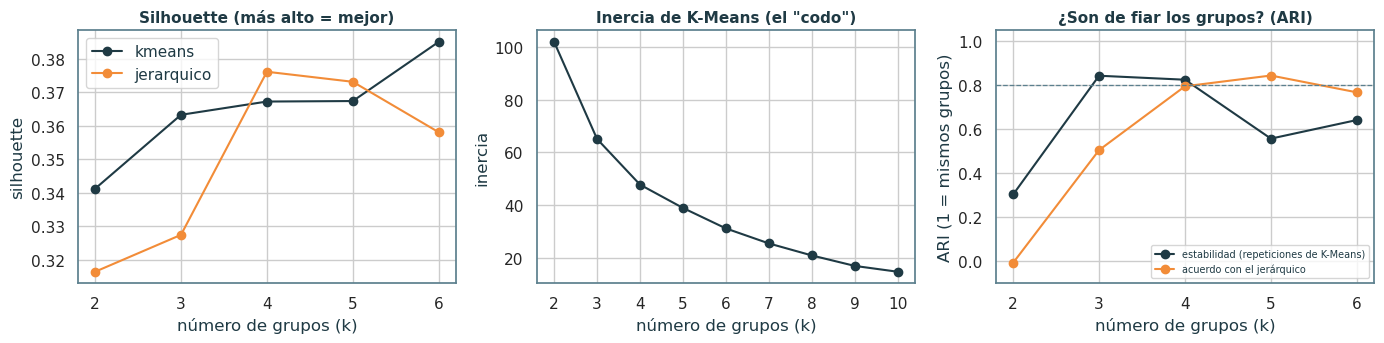

In [8]:
# Gráficos de las notas según el número de grupos (k)
fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
for algoritmo, color in zip(["kmeans", "jerarquico"], [AZUL, NARANJA]):
    datos = resultados[resultados["algoritmo"] == algoritmo]
    axes[0].plot(datos["k"], datos["silhouette"], marker="o", color=color, label=algoritmo)
axes[0].set_title("Silhouette (más alto = mejor)")
axes[0].set_ylabel("silhouette")
axes[0].legend()

km = resultados[resultados["algoritmo"] == "kmeans"]
# Para el codo calculamos la inercia de K-Means hasta k = 10 (es un cálculo rápido y no entra en la elección de k)
inercias_codo = [KMeans(n_clusters=k, n_init=N_INIT, random_state=RANDOM_STATE).fit(X).inertia_ for k in K_CODO]
axes[1].plot(list(K_CODO), inercias_codo, marker="o", color=AZUL)
axes[1].set_xticks(list(K_CODO))
axes[1].set_title("Inercia de K-Means (el \"codo\")")
axes[1].set_ylabel("inercia")

axes[2].plot(km["k"], km["estabilidad"], marker="o", color=AZUL, label="estabilidad (repeticiones de K-Means)")
axes[2].plot(km["k"], km["acuerdo_entre_algoritmos"], marker="o", color=NARANJA, label="acuerdo con el jerárquico")
axes[2].axhline(MIN_ESTABILIDAD, color=GRIS_AZULADO, linestyle="--", linewidth=0.9)
axes[2].set_title("¿Son de fiar los grupos? (ARI)")
axes[2].set_ylabel("ARI (1 = mismos grupos)")
axes[2].set_ylim(-0.1, 1.05)
axes[2].legend(fontsize=7, loc="lower right")

for ax in axes:
    ax.set_xlabel("número de grupos (k)")
for ax in (axes[0], axes[2]):
    ax.set_xticks(list(K_PROBADOS))
fig.tight_layout()
plt.show()

**Cómo leer los gráficos:**
- **Silhouette:** si hubiera un número de grupos claramente mejor, aparecería un pico. Aquí las líneas son casi planas: **el número de grupos no está marcado por los datos**.
- **Inercia:** baja siempre; el "codo" es donde deja de bajar con fuerza. Aquí la bajada es suave, sin un codo claro: hasta k = 10 se ve que, a partir de k = 5, la curva baja poco y de forma casi constante (casi una recta).
- **Fiabilidad:** la línea discontinua es el mínimo que pedimos de estabilidad. Con pocos grupos, K-Means da resultados distintos según el punto de partida y no coincide con el jerárquico.

Y debajo, el **dendrograma**: la altura a la que se unen las ramas dice lo distintos que son los platos.

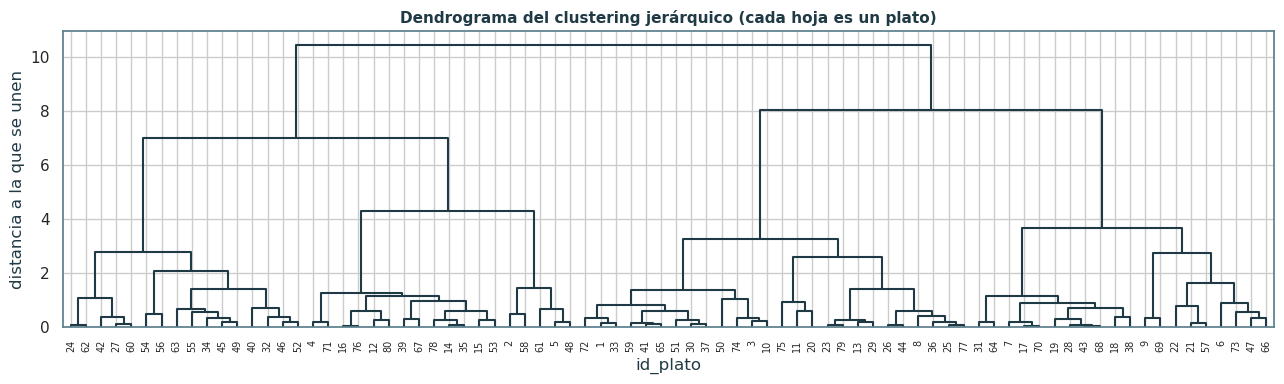

In [9]:
display(fig_dendro)

---
## 4. Elegir el número de grupos

Como las notas no señalan un ganador claro, **elegir el número de grupos *k* a ojo sería arbitrario**. Fijamos cuatro reglas **antes** de mirar el resultado (están en la celda de configuración) y elegimos el *k* **más pequeño** que las cumple todas (con la misma calidad, menos grupos son más fáciles de explicar):

| Regla | Qué pide | Por qué |
|---|---|---|
| **Silhouette cerca del mejor** | Como mucho 0,03 por debajo del mejor | No renunciar a mucha calidad. |
| **Estable** | Estabilidad ≥ 0,80 | Los grupos no cambian según el azar. |
| **Grupos no diminutos** | El grupo más pequeño tiene ≥ 10 % de los platos | Un grupo de 3 platos no es una categoría útil. |
| **Acuerdo con el jerárquico** | ARI ≥ 0,70 | Dos algoritmos distintos coinciden, así que los grupos no dependen de un método. |

**Cómo leer la tabla:** `True` = cumple la regla. El *k* elegido es el primero con todo en `True`.

In [10]:
k_final, reglas = elegir_k(resultados)
display(reglas)
print(f"\nNúmero de grupos elegido: k = {k_final}")

,silhouette cerca del mejor,estable,grupos no diminutos,acuerdo con el jerárquico,cumple todas
k,,,,,
2,False,False,True,False,False
3,True,True,True,False,False
4,True,True,True,True,True
5,True,False,False,True,False
6,True,False,False,True,False



Número de grupos elegido: k = 4


**Qué vemos:**
- **k = 2** falla en casi todo: K-Means no sale igual de una repetición a otra y ni siquiera coincide con el jerárquico.
- **k = 3** es estable, pero K-Means y el jerárquico agrupan distinto (acuerdo de 0,51, por debajo del 0,70 exigido).
- **k = 5 y k = 6** tienen grupos de solo 5 platos y son menos estables.
- **k = 4 es el primero que cumple las cuatro reglas**, y además sus cuatro grupos se corresponden con los cuatro **cuadrantes del negocio**: popular o no, y rentable o no.

---
## 5. Modelo final y perfil de los grupos

**El modelo final** es un **Pipeline** de dos pasos: estandarizar y agrupar con K-Means (*k* = el elegido). Al guardarlo como un solo objeto, un plato nuevo (con su popularidad y su margen) recibe **el mismo tratamiento** y se le asigna un grupo directamente.

**Por qué K-Means y no el jerárquico:** el jerárquico no sabe clasificar platos nuevos (solo agrupa los que ya tiene); K-Means sí, porque basta con ver cuál es su centroide más cercano. Por eso el jerárquico lo hemos usado para **comprobar** el resultado y K-Means es el modelo que guardamos.

**Poner nombre a los grupos:** un grupo cuyo centroide queda por encima de la media en popularidad y en margen es una *estrella*; por encima en una cosa y por debajo en la otra es *popular pero poco rentable* o *rentable pero poco popular*; por debajo en las dos, *bajo rendimiento*.

In [11]:
# Pipeline: primero estandariza, después agrupa con K-Means (mismos ajustes que en las pruebas)
modelo = Pipeline([
    ("estandarizar", StandardScaler()),
    ("kmeans", KMeans(n_clusters=k_final, n_init=N_INIT, random_state=RANDOM_STATE)),
])
modelo.fit(datos_modelo)                       # aprende la media/desviación y los centroides
grupos = modelo.predict(datos_modelo)          # grupo de cada plato (0, 1, 2…)

# Comprobación: el pipeline da la misma agrupación que la prueba K-Means del experimento
prueba_kmeans = KMeans(n_clusters=k_final, n_init=N_INIT, random_state=RANDOM_STATE).fit_predict(X)
validar(adjusted_rand_score(prueba_kmeans, grupos) == 1.0, "el modelo final coincide con la prueba K-Means de k = %d" % k_final)

# Centroides en las unidades reales (popularidad y euros) y estandarizados (0 = media de todos los platos)
centroides_z = modelo.named_steps["kmeans"].cluster_centers_
centroides_reales = modelo.named_steps["estandarizar"].inverse_transform(centroides_z)

# Nombre de cada grupo según su posición respecto a la media
nombres = nombrar_grupos(centroides_z)
validar(len(set(nombres.values())) == k_final, "cada grupo tiene un nombre distinto")

platos_grupos = platos.assign(grupo=grupos, nombre_grupo=[nombres[g] for g in grupos])
print({g: nombres[g] for g in sorted(nombres)})

OK · el modelo final coincide con la prueba K-Means de k = 4
OK · cada grupo tiene un nombre distinto
{0: 'Bajo rendimiento (poco popular y poco rentable)', 1: 'Rentable pero poco popular', 2: 'Estrella (popular y rentable)', 3: 'Popular pero poco rentable'}


**Cómo leer el perfil:** cada fila es un grupo y las columnas son la **media de sus platos**. La columna `n_platos` es el tamaño del grupo. Las dos últimas columnas dicen **cuánto se aleja el grupo de la media de todos los platos, en %**: por ejemplo, `+3,0` en popularidad significa que los platos de ese grupo se piden un 3 % más que la media.

In [12]:
# Perfil de cada grupo: media de cada variable + tamaño
perfil = platos_grupos.groupby("nombre_grupo")[VARIABLES_PERFIL].mean()
perfil.insert(0, "n_platos", platos_grupos.groupby("nombre_grupo").size())

# Cuánto se aleja cada grupo de la media de todos los platos (en %)
media_global = platos[VARIABLES_PERFIL].mean()
perfil["popularidad vs media (%)"] = (perfil["popularidad"] / media_global["popularidad"] - 1) * 100
perfil["margen vs media (%)"] = (perfil["margen_medio"] / media_global["margen_medio"] - 1) * 100
perfil = perfil.sort_values("popularidad", ascending=False)

display(perfil)
print("Media de todos los platos:")
display(media_global.to_frame("media").T)

,n_platos,popularidad,margen_medio,precio_medio,coste_medio,valoracion,dificultad,unidades_medias,popularidad vs media (%),margen vs media (%)
nombre_grupo,,,,,,,,,,
Popular pero poco rentable,13,0.514,9.744,15.788,6.043,4.146,5.462,24.581,2.230,-1.488
Estrella (popular y rentable),28,0.511,10.002,16.148,6.145,3.904,3.929,24.418,1.548,1.120
Bajo rendimiento (poco popular y poco rentable),21,0.495,9.758,15.803,6.046,3.829,4.048,23.999,-1.589,-1.353
Rentable pero poco popular,18,0.492,9.982,16.107,6.125,4.050,4.889,23.803,-2.165,0.911


Media de todos los platos:


,popularidad,margen_medio,precio_medio,coste_medio,valoracion,dificultad,unidades_medias
media,0.503,9.892,15.990,6.098,3.956,4.425,24.196


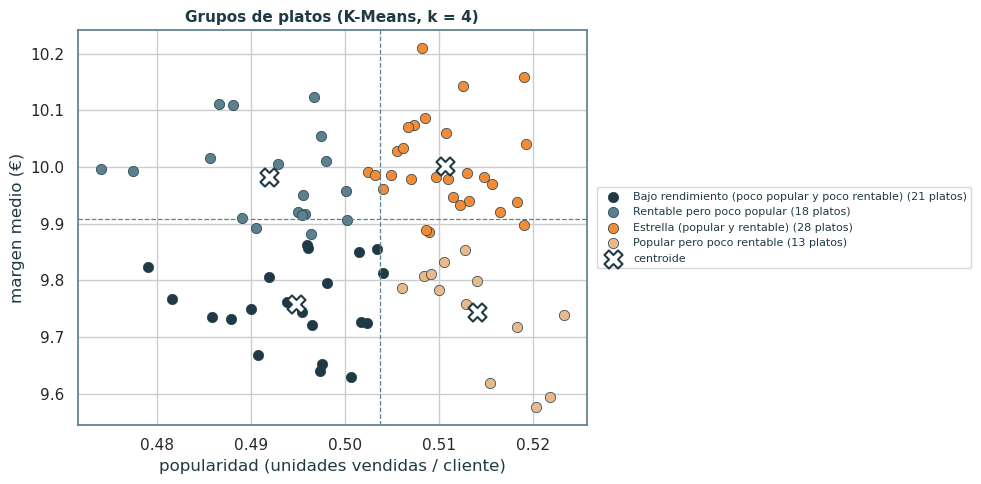

In [13]:
# Gráfico final: platos coloreados por grupo, con los centroides (X) y las medianas (líneas discontinuas)
fig_final = figura_grupos(platos, grupos, f"Grupos de platos (K-Means, k = {k_final})",
                          nombres=nombres, centroides=centroides_reales)
plt.show()

---
## 6. Registrar el modelo en MLflow

**Qué hacemos:** abrimos una ejecución nueva, `modelo_final`, y guardamos en ella todo lo que define el modelo:

- **Parámetros:** el algoritmo, *k*, las variables, la semilla y la huella de los datos.
- **Métricas:** las notas del modelo final.
- **Artefactos:** el gráfico de los grupos, el perfil de cada grupo y la tabla de platos con su grupo.
- **El modelo**, con su *firma* (qué columnas espera y qué devuelve) y un ejemplo de entrada.

Además **registramos el modelo** con nombre y versión y le ponemos el alias `actual`. Cada vez que se ejecute el notebook se crea una **versión nueva**, y el alias pasa a apuntar a ella.

In [14]:
# Notas del modelo final (las mismas que en las pruebas)
metricas_finales = evaluar_particion(X, grupos)
metricas_finales["inercia"] = modelo.named_steps["kmeans"].inertia_
metricas_finales["estabilidad"] = estabilidad_kmeans(X, k_final, grupos)
metricas_finales["acuerdo_entre_algoritmos"] = float(
    resultados.query("algoritmo == 'kmeans' and k == @k_final")["acuerdo_entre_algoritmos"].iloc[0])

# Firma del modelo: qué columnas entran y qué sale
firma = infer_signature(datos_modelo, grupos)

with mlflow.start_run(run_name="modelo_final") as run:
    mlflow.set_tag("fase", "final")
    mlflow.log_params({
        "algoritmo": "kmeans", "k": k_final, "variables": ",".join(VARIABLES), "preprocesado": "StandardScaler",
        "n_init": N_INIT, "random_state": RANDOM_STATE, "n_platos": len(platos), "huella_datos": huella_datos,
        "criterio_k": (f"menor k con silhouette a <={TOLERANCIA_SILHOUETTE} del mejor, estabilidad>={MIN_ESTABILIDAD}, "
                       f"grupo minimo>={MIN_TAM_GRUPO:.0%}, acuerdo>={MIN_ACUERDO}"),
    })
    mlflow.log_metrics(metricas_finales)
    mlflow.log_figure(fig_final, "grupos_finales.png")
    mlflow.log_text(perfil.round(4).to_csv(), "perfil_grupos.csv")
    mlflow.log_text(platos_grupos.round(6).to_csv(index=False), "platos_con_grupo.csv")

    # Guardamos el modelo y lo registramos con nombre (crea una versión nueva)
    mlflow.sklearn.log_model(modelo, artifact_path="modelo", signature=firma,
                             input_example=datos_modelo.head(3), registered_model_name=NOMBRE_MODELO)
    run_id_final = run.info.run_id

# Ponemos el alias "actual" en la versión que acabamos de crear
cliente = MlflowClient()
version = max((int(v.version) for v in cliente.search_model_versions(f"name='{NOMBRE_MODELO}'")
               if v.run_id == run_id_final))
cliente.set_registered_model_alias(NOMBRE_MODELO, ALIAS_MODELO, str(version))
cliente.update_model_version(NOMBRE_MODELO, str(version),
                             description=f"K-Means con k={k_final} sobre {', '.join(VARIABLES)} estandarizadas.")
print(f"Modelo '{NOMBRE_MODELO}' registrado: versión {version}, alias '{ALIAS_MODELO}'.")
print(f"Run del modelo final: {run_id_final}")

Registered model 'smart_restaurant_clustering_platos' already exists. Creating a new version of this model...
2026/11/24 10:16:41 INFO mlflow.store.model_registry.abstract_store: Waiting up to 300 seconds for model version to finish creation. Model name: smart_restaurant_clustering_platos, version 5


🏃 View run modelo_final at: http://mlflow:5000/#/experiments/1/runs/ec8d46e5ffd841eebfc5f5f7f12e96ce
🧪 View experiment at: http://mlflow:5000/#/experiments/1
Modelo 'smart_restaurant_clustering_platos' registrado: versión 5, alias 'actual'.
Run del modelo final: ec8d46e5ffd841eebfc5f5f7f12e96ce


Created version '5' of model 'smart_restaurant_clustering_platos'.


---
## 7. Comprobar que el modelo guardado funciona

**Qué hacemos:** guardar un modelo no basta; hay que comprobar que **se puede recuperar y que da lo mismo**. Lo cargamos desde MLflow por su nombre y su alias (`models:/nombre@alias`), le pasamos los 80 platos y comprobamos que asigna los mismos grupos. Después lo probamos con un **plato inventado** para ver cómo clasifica un plato nuevo.

In [15]:
# Recuperamos el modelo desde MLflow, igual que lo haría otra persona o otro notebook
modelo_cargado = mlflow.sklearn.load_model(f"models:/{NOMBRE_MODELO}@{ALIAS_MODELO}")

grupos_cargado = modelo_cargado.predict(datos_modelo)
validar(bool((grupos_cargado == grupos).all()), "el modelo recuperado de MLflow asigna los mismos grupos que el modelo entrenado")

# Un plato nuevo: se pide un poco por encima de la media y deja un margen alto
plato_nuevo = pd.DataFrame({"popularidad": [platos["popularidad"].quantile(0.9)],
                            "margen_medio": [platos["margen_medio"].quantile(0.9)]})
g_nuevo = int(modelo_cargado.predict(plato_nuevo)[0])
print(f"Plato nuevo -> popularidad {plato_nuevo.iloc[0, 0]:.3f}, margen {plato_nuevo.iloc[0, 1]:.2f} €")
print(f"Grupo asignado: {g_nuevo} · {nombres[g_nuevo]}")

OK · el modelo recuperado de MLflow asigna los mismos grupos que el modelo entrenado
Plato nuevo -> popularidad 0.517, margen 10.07 €
Grupo asignado: 2 · Estrella (popular y rentable)


---
## 8. Guardar el resultado

Guardamos en HDFS la tabla de platos con su grupo (`platos_clusters.parquet`) para poder usarla en el dashboard o en el informe. Es la tabla de 80 platos del notebook 03 más dos columnas nuevas: `grupo` (0, 1, 2…) y `nombre_grupo`.

In [16]:
COLUMNAS_SALIDA = ["id_plato", "grupo", "nombre_grupo"] + VARIABLES_PERFIL + ["n_filas"]
guardar_parquet(platos_grupos[COLUMNAS_SALIDA], RUTA_CLUSTERS)
display(platos_grupos[COLUMNAS_SALIDA].head())

OK · guardado en clean/ventas_diarias_platos/platos_clusters.parquet · 80 filas × 11 columnas


,id_plato,grupo,nombre_grupo,popularidad,margen_medio,precio_medio,coste_medio,valoracion,dificultad,unidades_medias,n_filas
0,1,2,Estrella (popular y rentable),0.510,9.983,16.151,6.168,4.000,4,24.542,1311
1,2,3,Popular pero poco rentable,0.518,9.718,15.749,6.032,4.800,7,24.619,1264
2,3,2,Estrella (popular y rentable),0.518,9.939,16.028,6.089,4.900,7,25.088,1285
3,4,0,Bajo rendimiento (poco popular y poco rentable),0.502,9.851,15.834,5.983,3.900,3,24.592,1331
4,5,3,Popular pero poco rentable,0.522,9.594,15.685,6.091,4.100,7,25.143,1294


---
## 9. Cómo verlo en MLflow

Abre **http://localhost:5000** en el navegador:

1. **Experiments → `smart-restaurant-clustering-platos`.** Verás la lista de ejecuciones. Cada `comparacion_algoritmos_y_k` tiene dentro sus 10 pruebas hijas (pulsa la flecha para desplegarlas) y `modelo_final` es la del modelo definitivo.
2. **Comparar pruebas:** marca varias casillas y pulsa **Compare**. Se ven los parámetros y las métricas lado a lado, y los gráficos de dispersión de cada una.
3. **Abrir una ejecución:** en la pestaña **Artifacts** están los gráficos (`grupos.png`, `grupos_finales.png`, `dendrograma.png`), el perfil de los grupos y la tabla de platos con su grupo.
4. **Models → `smart_restaurant_clustering_platos`:** las versiones del modelo registrado y cuál tiene el alias `actual`.

Para leer los resultados desde código también se puede usar `mlflow.search_runs(...)`, que devuelve una tabla con todas las ejecuciones. Aquí la usamos para comprobar que todo se ha guardado:

In [17]:
# Todas las ejecuciones de la última comparación, leídas desde MLflow
guardadas = mlflow.search_runs(experiment_ids=[experimento.experiment_id], filter_string="tags.fase = 'comparacion'",
                               order_by=["attributes.start_time DESC"], max_results=11)
columnas_mlflow = ["tags.mlflow.runName", "params.algoritmo", "params.k", "metrics.silhouette", "metrics.estabilidad"]
display(guardadas[columnas_mlflow].rename(columns=lambda c: c.split(".", 1)[-1]).reset_index(drop=True))

,mlflow.runName,algoritmo,k,silhouette,estabilidad
0,jerarquico_k6,jerarquico,6,0.358,NaN
1,kmeans_k6,kmeans,6,0.385,0.642
2,jerarquico_k5,jerarquico,5,0.373,NaN
3,kmeans_k5,kmeans,5,0.367,0.558
4,jerarquico_k4,jerarquico,4,0.376,NaN
5,kmeans_k4,kmeans,4,0.367,0.825
6,jerarquico_k3,jerarquico,3,0.327,NaN
7,kmeans_k3,kmeans,3,0.363,0.844
8,jerarquico_k2,jerarquico,2,0.316,NaN
9,kmeans_k2,kmeans,2,0.341,0.304


---
## 10. Conclusiones

**En una frase:** agrupamos los 80 platos en **4 grupos** con K-Means según su popularidad y su margen; los grupos son útiles para **priorizar y comunicar**, pero hay que presentarlos como **tramos de un espectro** (los platos se parecen mucho entre sí), no como categorías muy separadas.

**Sobre el modelo**
- **Algoritmo:** K-Means (con las dos variables estandarizadas, dentro de un Pipeline) con **k = 4**. El clustering jerárquico se usó para comprobar el resultado: coincide bastante con K-Means (ARI de 0,80).
- **Por qué k = 4:** es el *k* más pequeño que cumple las cuatro reglas fijadas de antemano: silhouette cerca del mejor (0,367 frente a 0,385 del mejor), estable al repetir (0,83), grupos no diminutos (de 13 a 28 platos) y acuerdo con el jerárquico (0,80). Con 2 y 3 grupos fallan la estabilidad o el acuerdo; con 5 y 6 aparecen grupos de 5 platos.
- **Todo queda registrado en MLflow:** las 10 pruebas, sus parámetros, métricas y gráficos, y el modelo final como `smart_restaurant_clustering_platos` (alias `actual`). Se comprobó que el modelo recuperado de MLflow asigna exactamente los mismos grupos.

**Los 4 grupos**

| Grupo | Platos | Popularidad | Margen medio |
|---|---|---|---|
| Estrella (popular y rentable) | 28 | 0,511 | 10,00 € |
| Popular pero poco rentable | 13 | 0,514 | 9,74 € |
| Rentable pero poco popular | 18 | 0,492 | 9,98 € |
| Bajo rendimiento (poco popular y poco rentable) | 21 | 0,495 | 9,76 € |

La media de todos los platos es 0,503 de popularidad y 9,89 € de margen.

**Qué hay que tener en cuenta al presentarlo**
- **Las diferencias entre grupos son pequeñas:** cada grupo se aleja de la media alrededor de un 2 % en popularidad y entre un 1 % y un 1,5 % en margen. El silhouette (0,37) indica una estructura **débil**: no hay islas de platos claramente separadas, sino una nube continua que K-Means divide en cuatro zonas.
- **Esto no invalida el modelo:** sirve para ordenar los platos (por ejemplo, ver cuáles combinan popularidad y margen) y para decidir dónde mirar primero. Pero conviene hablar de «platos que tiran a populares y rentables» más que de «platos estrella» en sentido absoluto.
- **Los datos son sintéticos** y los platos se parecen mucho por cómo se generaron; hay que decirlo al presentar los resultados.
- Valoración y dificultad **no se usaron para agrupar**, pero describen un poco los grupos: el grupo *Popular pero poco rentable* tiene los platos mejor valorados (4,15) y más difíciles (5,5).

**Siguientes pasos**
- Usar `platos_clusters.parquet` en el dashboard (por ejemplo, una página con los grupos y la lista de platos de cada uno).
- Pasar al modelo del objetivo 2 (regresión del tiempo de preparación), usando MLflow de la misma manera.